
# Clasificación de registros de bacalao del Atlántico mediante Aprendizaje Automático

**Proyecto final — ICES-DATRAS, campañas NS-IBTS Q1 (2020–2025)**

### Presentación del proyecto

Este proyecto utiliza datos de las campañas científicas NS-IBTS, correspondientes al primer trimestre de los años 2020 a 2025, disponibles en la base ICES-DATRAS.

Se aborda un problema de clasificación supervisada binaria, orientado a identificar patrones asociados con los registros de bacalao del Atlántico (*Gadus morhua*) en lances de investigación pesquera del mar del Norte.

### Objetivo general

Desarrollar y evaluar un modelo de Aprendizaje Automático que permita estimar la probabilidad de registrar bacalao del Atlántico en futuros lances de investigación pesquera, utilizando características de profundidad y ubicación geográfica.

### Objetivos específicos

- Explorar y analizar los datos de las campañas NS-IBTS Q1 correspondientes al período 2020–2025.
- Identificar los lances válidos y establecer criterios de preparación y selección de los registros.
- Construir una variable objetivo binaria que diferencie los lances con registros de bacalao de aquellos sin registros.
- Entrenar y evaluar un modelo de regresión logística utilizando profundidad (Depth), latitud (ShootLat) y longitud (ShootLong) como variables predictoras.
- Analizar el desempeño del modelo mediante métricas de clasificación e identificar sus principales limitaciones.

### Consideraciones sobre las variables predictoras

Dado que se busca realizar predicciones antes del muestreo, es necesario disponer previamente de información sobre la profundidad del fondo marino, comparable con los valores utilizados durante el entrenamiento.

La duración efectiva del lance (HaulDur) se conservará para el análisis exploratorio, pero no se utilizará como variable predictora porque no se conoce antes de realizar el muestreo.

Las predicciones se refieren a la posibilidad de obtener registros de bacalao durante un lance y no permiten determinar la presencia o ausencia real de la especie en una zona marítima.



In [1]:
import pandas as pd
from pathlib import Path

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


In [2]:
ruta_csv = Path("../data/raw/datras_ns_ibts_2020_2025_original.csv")

print("¿Existe el archivo?", ruta_csv.exists())
print("Ubicación:", ruta_csv.resolve())

¿Existe el archivo? True
Ubicación: C:\Users\veneg\Documents\Proyectos\clasificacion-bacalao-atlantico\data\raw\datras_ns_ibts_2020_2025_original.csv


In [3]:
from collections import Counter

conteo_registros = Counter()

with open(ruta_csv, "r", encoding="utf-8-sig") as archivo:
    for linea in archivo:
        tipo = linea.split(",")[0].strip()
        conteo_registros[tipo] += 1

print("Tipos de registros encontrados:")
for tipo, cantidad in conteo_registros.items():
    print(f"{tipo}: {cantidad}")

Tipos de registros encontrados:
RecordType: 2
HH: 2034
HL: 134934


### Identificación de los tipos de registros

El archivo original de ICES-DATRAS contiene dos tipos de registros:

- **HH (Haul Header – Cabecera del lance):** 2.034 registros con información general de los lances de investigación pesquera, como ubicación, profundidad y duración.
- **HL (Haul Length – Registros de longitud por lance):** 134.934 registros con información biológica de las especies registradas durante los muestreos.

Además, se identificaron dos filas de encabezado que permiten distinguir la estructura de ambas secciones.

Esta organización requiere analizar las tablas por separado y posteriormente relacionarlas mediante los identificadores de los lances.

Para construir el conjunto de datos de clasificación, se buscará conservar una observación por lance, verificando previamente su validez y los criterios de registro de la especie estudiada.

In [4]:
import csv

registros_hh = []
registros_hl = []
encabezados_hh = None
encabezados_hl = None

with open(ruta_csv, "r", encoding="utf-8-sig", newline="") as archivo:
    lector = csv.reader(archivo)

    for fila in lector:
        if not fila:
            continue

        if fila[0] == "RecordType":
            if "HaulDur" in fila:
                encabezados_hh = fila
            elif "ScientificName_WoRMS" in fila:
                encabezados_hl = fila

        elif fila[0] == "HH":
            registros_hh.append(fila)

        elif fila[0] == "HL":
            registros_hl.append(fila)

df_hh = pd.DataFrame(registros_hh, columns=encabezados_hh)
df_hl = pd.DataFrame(registros_hl, columns=encabezados_hl)

print("Tabla HH:", df_hh.shape)
print("Tabla HL:", df_hl.shape)

Tabla HH: (2034, 71)
Tabla HL: (134934, 30)


In [5]:
display(df_hh.head())
display(df_hl.head())

,RecordType,Survey,Quarter,Country,Ship,Gear,SweepLngt,GearEx,DoorType,StNo,...,SecchiDepth,Turbidity,TidePhase,TideSpeed,PelSampType,MinTrawlDepth,MaxTrawlDepth,SurveyIndexArea,ReasonHaulDisruption,DateofCalculation
0,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,6,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625
1,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,8,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625
2,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,10,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625
3,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,11,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625
4,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,19,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625


,RecordType,Survey,Quarter,Country,Ship,Gear,SweepLngt,GearEx,DoorType,StNo,...,SubWgt,CatCatchWgt,LngtCode,LngtClass,HLNoAtLngt,DevStage,LenMeasType,ValidAphiaID,ScientificName_WoRMS,DateofCalculation
0,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,250,4.00,-9,-9,126438,Merlangius merlangus,20260625
1,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,260,4.00,-9,-9,126438,Merlangius merlangus,20260625
2,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,270,8.00,-9,-9,126438,Merlangius merlangus,20260625
3,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,280,4.00,-9,-9,126438,Merlangius merlangus,20260625
4,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,290,14.00,-9,-9,126438,Merlangius merlangus,20260625


In [6]:
print("COLUMNAS DE LA TABLA HH:")
print(df_hh.columns.tolist())

print("\nCOLUMNAS DE LA TABLA HL:")
print(df_hl.columns.tolist())

COLUMNAS DE LA TABLA HH:
['RecordType', 'Survey', 'Quarter', 'Country', 'Ship', 'Gear', 'SweepLngt', 'GearEx', 'DoorType', 'StNo', 'HaulNo', 'Year', 'Month', 'Day', 'TimeShot', 'DepthStratum', 'HaulDur', 'DayNight', 'ShootLat', 'ShootLong', 'HaulLat', 'HaulLong', 'StatRec', 'Depth', 'HaulVal', 'HydroStNo', 'StdSpecRecCode', 'BySpecRecCode', 'DataType', 'Netopening', 'Rigging', 'Tickler', 'Distance', 'Warplngt', 'Warpdia', 'WarpDen', 'DoorSurface', 'DoorWgt', 'DoorSpread', 'WingSpread', 'Buoyancy', 'KiteDim', 'WgtGroundRope', 'TowDir', 'GroundSpeed', 'SpeedWater', 'SurCurDir', 'SurCurSpeed', 'BotCurDir', 'BotCurSpeed', 'WindDir', 'WindSpeed', 'SwellDir', 'SwellHeight', 'SurTemp', 'BotTemp', 'SurSal', 'BotSal', 'ThermoCline', 'ThClineDepth', 'CodendMesh', 'SecchiDepth', 'Turbidity', 'TidePhase', 'TideSpeed', 'PelSampType', 'MinTrawlDepth', 'MaxTrawlDepth', 'SurveyIndexArea', 'ReasonHaulDisruption', 'DateofCalculation']

COLUMNAS DE LA TABLA HL:
['RecordType', 'Survey', 'Quarter', 'Countr

In [7]:
with open(ruta_csv, "r", encoding="utf-8-sig") as archivo:
    for linea in archivo:
        if linea.startswith("RecordType") and "HaulDur" not in linea:
            print(linea.strip())
            break

RecordType,Survey,Quarter,Country,Ship,Gear,SweepLngt,GearEx,DoorType,StNo,HaulNo,Year,SpecCodeType,SpecCode,SpecVal,Sex,TotalNo,CatIdentifier,NoMeas,SubFactor,SubWgt,CatCatchWgt,LngtCode,LngtClass,HLNoAtLngt,DevStage,LenMeasType,ValidAphiaID,ScientificName_WoRMS,DateofCalculation


In [8]:
print("Columnas de la tabla HL:")
print(df_hl.columns.tolist())

Columnas de la tabla HL:
['RecordType', 'Survey', 'Quarter', 'Country', 'Ship', 'Gear', 'SweepLngt', 'GearEx', 'DoorType', 'StNo', 'HaulNo', 'Year', 'SpecCodeType', 'SpecCode', 'SpecVal', 'Sex', 'TotalNo', 'CatIdentifier', 'NoMeas', 'SubFactor', 'SubWgt', 'CatCatchWgt', 'LngtCode', 'LngtClass', 'HLNoAtLngt', 'DevStage', 'LenMeasType', 'ValidAphiaID', 'ScientificName_WoRMS', 'DateofCalculation']


In [9]:
# Seleccionar los registros de bacalao del Atlántico
df_bacalao = df_hl[
    df_hl["ScientificName_WoRMS"] == "Gadus morhua"
].copy()

print("Registros biológicos totales:", len(df_hl))
print("Registros de Gadus morhua:", len(df_bacalao))

display(df_bacalao[
    ["Year", "Country", "Ship", "HaulNo",
     "ScientificName_WoRMS", "LngtClass", "HLNoAtLngt"]
].head(10))

Registros biológicos totales: 134934
Registros de Gadus morhua: 7557


,Year,Country,Ship,HaulNo,ScientificName_WoRMS,LngtClass,HLNoAtLngt
15,2020,FR,35HT,6,Gadus morhua,460,2.00
126,2020,GB-SCT,748S,41,Gadus morhua,330,1.00
127,2020,GB-SCT,748S,41,Gadus morhua,850,1.00
128,2020,GB-SCT,748S,41,Gadus morhua,1000,1.00
187,2020,GB-SCT,748S,43,Gadus morhua,270,1.00
188,2020,GB-SCT,748S,43,Gadus morhua,310,1.00
243,2020,GB-SCT,748S,44,Gadus morhua,310,1.00
244,2020,GB-SCT,748S,44,Gadus morhua,360,1.00
245,2020,GB-SCT,748S,44,Gadus morhua,650,1.00
282,2020,GB-SCT,748S,40,Gadus morhua,320,2.00


In [10]:
# Columnas propuestas para identificar cada lance
columnas_id = [
    "Survey", "Quarter", "Year",
    "Country", "Ship", "Gear", "HaulNo", "StNo"
]

# Contar combinaciones únicas entre los registros de bacalao
lances_bacalao = df_bacalao[columnas_id].drop_duplicates()

print("Registros biológicos de bacalao:", len(df_bacalao))
print("Combinaciones únicas de lance con bacalao:", len(lances_bacalao))

Registros biológicos de bacalao: 7557
Combinaciones únicas de lance con bacalao: 1354


In [11]:
# Verificar la identificación única de los lances en HH

total_hh = len(df_hh)
lances_unicos_hh = df_hh[columnas_id].drop_duplicates().shape[0]
duplicados_hh = df_hh.duplicated(subset=columnas_id).sum()

print("Total de registros HH:", total_hh)
print("Lances únicos identificados:", lances_unicos_hh)
print("Registros duplicados según el identificador:", duplicados_hh)

Total de registros HH: 2034
Lances únicos identificados: 2034
Registros duplicados según el identificador: 0


In [12]:
# Verificar que los lances con bacalao existan en la tabla HH

verificacion = lances_bacalao.merge(
    df_hh[columnas_id],
    on=columnas_id,
    how="left",
    indicator=True
)

print("Lances con bacalao identificados:", len(verificacion))

print("\nCorrespondencia con la tabla HH:")
print(verificacion["_merge"].value_counts())

Lances con bacalao identificados: 1354

Correspondencia con la tabla HH:
_merge
both          1354
left_only        0
right_only       0
Name: count, dtype: int64


In [13]:
print("Distribución de códigos de validez:")
print(df_hh["HaulVal"].value_counts(dropna=False))

print("\nRegistros de bacalao según código de validez:")

verificacion_validez = verificacion.merge(
    df_hh[columnas_id + ["HaulVal"]],
    on=columnas_id,
    how="left"
)

print(verificacion_validez["HaulVal"].value_counts(dropna=False))

Distribución de códigos de validez:
HaulVal
V    1970
I      57
A       7
Name: count, dtype: int64

Registros de bacalao según código de validez:
HaulVal
V    1335
I      15
A       4
Name: count, dtype: int64


### Evaluación de la validez de los lances

Se identificaron 1.970 lances válidos (V), 57 inválidos (I) y 7 estaciones adicionales (A), según la codificación de ICES-DATRAS.

Para la construcción del conjunto de datos de clasificación, se seleccionaron únicamente los lances con código V (HaulVal = V), excluyendo los registros con códigos I y A.

Entre los 1.970 lances válidos, 1.335 presentan registros de bacalao del Atlántico y 635 no presentan registros de la especie en la tabla biológica.

Estos últimos no se consideran automáticamente como ausencia de bacalao, ya que es necesario verificar la integridad de la información biológica del muestreo antes de asignarles la clase negativa.

**Fuente:** ICES-DATRAS, Reference Codes, TS_HaulVal.


In [14]:
# Seleccionar los lances válidos
df_validos = df_hh[df_hh["HaulVal"] == "V"].copy()

# Identificar los lances con información biológica
lances_hl = df_hl[columnas_id].drop_duplicates()

# Comprobar la correspondencia
control_biologico = df_validos.merge(
    lances_hl,
    on=columnas_id,
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("Total de lances válidos:", len(df_validos))

print("\nCorrespondencia con los registros biológicos:")
print(control_biologico["_merge"].value_counts())

Total de lances válidos: 1970

Correspondencia con los registros biológicos:
_merge
both          1970
left_only        0
right_only       0
Name: count, dtype: int64


### Verificación de la información biológica

Se comprobó que los 1.970 lances clasificados como válidos (HaulVal = V) tienen registros asociados en la tabla biológica HL.
De ellos, 1.335 presentan registros de bacalao del Atlántico (*Gadus morhua*), mientras que 635 no presentan registros de la especie.

Esta correspondencia permite avanzar en la construcción de la variable objetivo binaria. Antes de asignar definitivamente la clase 0, se verificarán los códigos de registro y la integridad de la información biológica para evitar interpretar automáticamente la falta de registros de bacalao como ausencia real de la especie.


In [15]:
# Revisar los códigos de registro de especies
# en los lances válidos

print("Códigos de especies estándar:")
print(df_validos["StdSpecRecCode"].value_counts(dropna=False))

print("\nCódigos de especies acompañantes:")
print(df_validos["BySpecRecCode"].value_counts(dropna=False))

print("\nCombinaciones de ambos códigos:")
display(
    df_validos.groupby(
        ["StdSpecRecCode", "BySpecRecCode"]
    ).size().reset_index(name="Cantidad de lances")
)

Códigos de especies estándar:
StdSpecRecCode
1    1970
Name: count, dtype: int64

Códigos de especies acompañantes:
BySpecRecCode
1    1970
Name: count, dtype: int64

Combinaciones de ambos códigos:


,StdSpecRecCode,BySpecRecCode,Cantidad de lances
0,1,1,1970


In [16]:
print("Códigos SpecVal de todos los registros biológicos:")
print(df_hl["SpecVal"].value_counts(dropna=False))

print("\nCódigos SpecVal de Gadus morhua:")
print(df_bacalao["SpecVal"].value_counts(dropna=False))

print("\nCódigos y cantidad de lances con bacalao:")
display(
    df_bacalao.groupby("SpecVal")[columnas_id]
    .apply(lambda x: x.drop_duplicates().shape[0])
    .reset_index(name="Cantidad de lances")
)

Códigos SpecVal de todos los registros biológicos:
SpecVal
1     134077
0        811
10        44
6          2
Name: count, dtype: int64

Códigos SpecVal de Gadus morhua:
SpecVal
1    7477
0      80
Name: count, dtype: int64

Códigos y cantidad de lances con bacalao:


,SpecVal,Cantidad de lances
0,0,15
1,1,1339


In [17]:
# Identificar combinaciones de lance y validez de bacalao
validez_bacalao = df_bacalao[
    columnas_id + ["SpecVal"]
].drop_duplicates()

# Incorporar la validez del lance desde HH
cruce_validez = validez_bacalao.merge(
    df_hh[columnas_id + ["HaulVal"]],
    on=columnas_id,
    how="left",
    validate="many_to_one"
)

# Resumen de ambas condiciones
tabla_validez = pd.crosstab(
    cruce_validez["HaulVal"],
    cruce_validez["SpecVal"]
)

display(tabla_validez)

SpecVal,0,1
HaulVal,,
A,0,4
I,15,0
V,0,1335


### Verificación cruzada de la validez de los registros

Se compararon los códigos de validez de los lances
(HaulVal) con los códigos de validez de los registros
biológicos de bacalao (SpecVal).

Se comprobó que los 1.335 lances válidos con registros
de Gadus morhua presentan información biológica válida.

Los registros restantes de bacalao corresponden a
15 lances inválidos y 4 estaciones adicionales.

Para construir el conjunto de datos de clasificación
se trabajará inicialmente con los 1.970 lances válidos.

De estos, 1.335 tienen registros válidos de bacalao
y 635 no presentan registros de la especie.

La ausencia de registros se interpretará únicamente
como ausencia de detección documentada durante el lance,
sin asumir que la especie está ausente de la zona.

In [18]:
# Identificar lances válidos sin registros de bacalao
lances_sin_bacalao = df_validos[columnas_id].merge(
    lances_bacalao,
    on=columnas_id,
    how="left",
    indicator=True
)

lances_sin_bacalao = lances_sin_bacalao[
    lances_sin_bacalao["_merge"] == "left_only"
][columnas_id].copy()

# Obtener sus registros biológicos
hl_sin_bacalao = df_hl.merge(
    lances_sin_bacalao,
    on=columnas_id,
    how="inner"
)

print("Lances válidos sin registros de bacalao:",
      len(lances_sin_bacalao))

print("\nCódigos de validez de sus registros biológicos:")
print(hl_sin_bacalao["SpecVal"].value_counts(dropna=False))

print("\nLances con al menos un registro biológico válido:")
lances_con_registro_valido = hl_sin_bacalao[
    hl_sin_bacalao["SpecVal"] == "1"
][columnas_id].drop_duplicates()

print(len(lances_con_registro_valido))

Lances válidos sin registros de bacalao: 635

Códigos de validez de sus registros biológicos:
SpecVal
1     34408
0         2
10        2
6         1
Name: count, dtype: int64

Lances con al menos un registro biológico válido:
635


### Revisión de los lances sin registros de bacalao

Se identificaron 635 lances válidos sin registros de
Gadus morhua en la tabla biológica HL.

Al examinar su información se encontraron 34.413
registros biológicos, de los cuales 34.408 presentan
el código de validez 1.

Se comprobó que los 635 lances cuentan con al menos
un registro biológico válido de otras especies.

Estos resultados respaldan la utilización de dichos
lances como candidatos a la clase 0. Sin embargo,
la interpretación definitiva dependerá de los
criterios de registro de especies establecidos
por ICES-DATRAS.

La clase 0 representará la falta de registro de
bacalao durante un lance válido, sin afirmar
que la especie esté ausente de la zona.

In [19]:
# Variables numéricas seleccionadas para el análisis exploratorio
variables_predictoras = [
    "Depth", "ShootLat", "ShootLong", "HaulDur"
]

# Revisar sus tipos de datos originales
print("Tipos de datos de las variables:")
print(df_validos[variables_predictoras].dtypes)

# Mostrar los primeros registros
display(df_validos[variables_predictoras].head(10))

Tipos de datos de las variables:
Depth        str
ShootLat     str
ShootLong    str
HaulDur      str
dtype: object


,Depth,ShootLat,ShootLong,HaulDur
0,35,56.6076,7.1445,30
1,45,56.5951,6.8874,30
2,33,56.3057,7.1858,30
3,36,56.3333,6.8544,30
4,73,56.7180,2.4918,30
5,98,56.7494,1.5045,30
6,84,56.0677,1.1718,30
7,91,56.2319,0.8764,30
8,47,55.4404,5.4512,30
9,46,55.5810,5.0686,30


In [20]:
import numpy as np

# Crear una copia de los lances válidos
df_variables = df_validos.copy()

# Convertir las variables predictoras a formato numérico
for columna in variables_predictoras:
    df_variables[columna] = pd.to_numeric(
        df_variables[columna],
        errors="coerce"
    )

# Identificar el código de dato faltante
df_variables[variables_predictoras] = (
    df_variables[variables_predictoras].replace(-9, np.nan)
)

print("Tipos de datos después de la conversión:")
print(df_variables[variables_predictoras].dtypes)

print("\nValores faltantes por variable:")
print(df_variables[variables_predictoras].isna().sum())

Tipos de datos después de la conversión:
Depth          int64
ShootLat     float64
ShootLong    float64
HaulDur        int64
dtype: object

Valores faltantes por variable:
Depth        0
ShootLat     0
ShootLong    0
HaulDur      0
dtype: int64


In [21]:
# Estadísticas descriptivas de las variables numéricas analizadas

estadisticas = df_variables[variables_predictoras].describe()

display(estadisticas.round(2))

,Depth,ShootLat,ShootLong,HaulDur
count,1970.00,1970.00,1970.00,1970.00
mean,74.94,56.47,3.34,29.27
std,44.22,2.61,3.94,2.66
min,14.00,49.57,-3.96,15.00
25%,40.00,54.72,0.52,30.00
50%,65.00,56.68,2.67,30.00
75%,102.00,58.21,5.70,30.00
max,260.00,61.74,12.61,34.00


### Análisis descriptivo de las variables numéricas

Se analizaron cuatro variables numéricas de los 1.970 lances válidos. Después de convertirlas a formato numérico y tratar los códigos de datos faltantes, no se identificaron valores ausentes.

La profundidad de los muestreos varía entre 14 y 260 metros, con un promedio de 74,94 metros. Las coordenadas geográficas muestran diferencias en las ubicaciones donde se realizaron los lances.

La duración presenta un promedio de 29,27 minutos y una mediana de 30 minutos, lo que indica que los muestreos tienen duraciones relativamente similares.

Estas características se analizarán para explorar su posible relación con los registros de bacalao del Atlántico. Para entrenar el modelo se utilizarán únicamente la profundidad, la latitud y la longitud. La duración se conservará como información descriptiva porque no se conoce antes del muestreo.


**Selección y codificación de variables**

Para entrenar el modelo se seleccionaron tres variables numéricas: profundidad (Depth), latitud (ShootLat) y longitud (ShootLong). Por este motivo, no fue necesario aplicar técnicas de codificación de variables categóricas. Las demás variables del dataset se conservaron para el análisis y la documentación, pero no se utilizaron como predictoras.


## Análisis exploratorio gráfico (EDA)

### Distribución de la profundidad de los lances

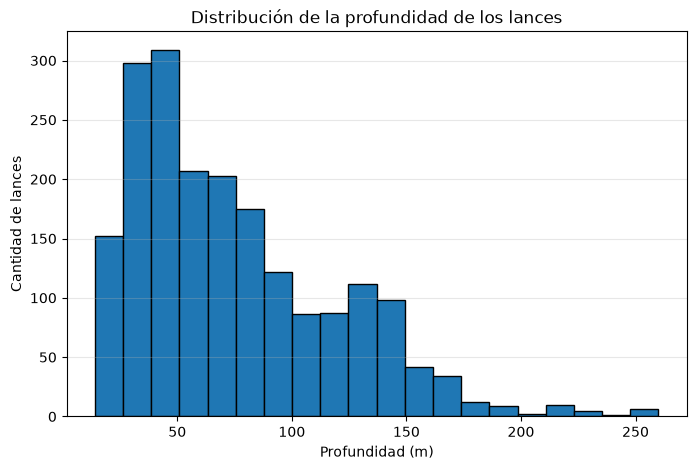

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_variables["Depth"], bins=20, edgecolor="black")

plt.title("Distribución de la profundidad de los lances")
plt.xlabel("Profundidad (m)")
plt.ylabel("Cantidad de lances")

plt.grid(axis="y", alpha=0.3)
plt.show()

### Interpretación de la distribución de profundidades

El histograma muestra que la mayor concentración de lances se encuentra en profundidades relativamente bajas, principalmente entre 25 y 90 metros.

La distribución presenta una asimetría hacia la derecha, con una disminución progresiva de la frecuencia en profundidades mayores. Esto coincide con una media de 74,94 metros, superior a la mediana de 65 metros.

También se observan algunos lances en profundidades superiores a 200 metros, menos frecuentes dentro del conjunto de datos. Estos valores no necesariamente representan errores y deben interpretarse considerando las características de las zonas de muestreo.

Este análisis describe las profundidades de los muestreos, pero todavía no permite establecer una relación con los registros de bacalao del Atlántico.

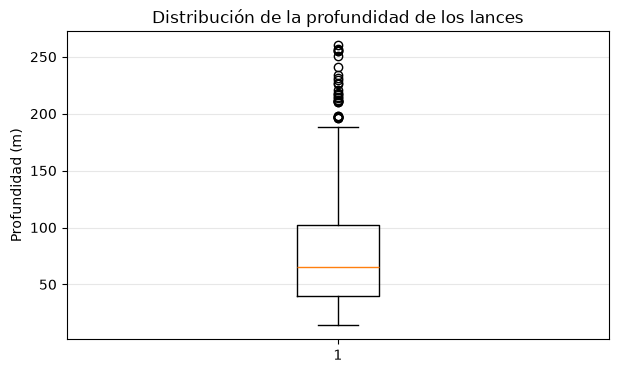

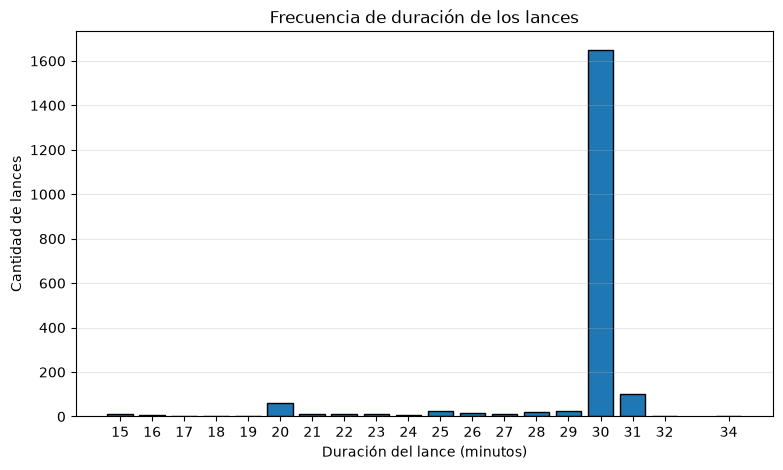

In [23]:
# Boxplot de profundidad
plt.figure(figsize=(7, 4))
plt.boxplot(df_variables["Depth"])

plt.title("Distribución de la profundidad de los lances")
plt.ylabel("Profundidad (m)")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Gráfico de barras de duración
frecuencia_duracion = df_variables["HaulDur"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
plt.bar(
    frecuencia_duracion.index,
    frecuencia_duracion.values,
    edgecolor="black"
)

plt.title("Frecuencia de duración de los lances")
plt.xlabel("Duración del lance (minutos)")
plt.ylabel("Cantidad de lances")
plt.xticks(frecuencia_duracion.index)
plt.grid(axis="y", alpha=0.3)
plt.show()

### Interpretación de la profundidad y duración de los lances

El boxplot de profundidad muestra una mediana de 65 metros y un rango intercuartílico entre 40 y 102 metros. Se identifican posibles valores atípicos por encima de aproximadamente 195 metros, que no necesariamente representan errores y, por lo tanto, se conservarán para el análisis.

El gráfico de barras de duración evidencia que la mayoría de los lances se concentra en los 30 minutos, mientras que las demás duraciones presentan frecuencias considerablemente menores.

Estos resultados permiten reconocer diferencias en la distribución de ambas variables. La profundidad presenta una mayor dispersión, mientras que la duración se concentra principalmente en un valor.

Para el modelo de clasificación se utilizará la profundidad junto con las coordenadas geográficas. La duración efectiva del lance se conservará únicamente para el análisis exploratorio, ya que no se conoce antes de realizar el muestreo.


In [24]:
# Identificar lances válidos con registros válidos de bacalao
bacalao_valido = df_bacalao[
    df_bacalao["SpecVal"] == "1"
][columnas_id].drop_duplicates()

# Crear dataset con los lances válidos
df_modelo = df_variables.merge(
    bacalao_valido.assign(presencia_bacalao=1),
    on=columnas_id,
    how="left",
    validate="one_to_one"
)

# Asignar clase 0 a lances sin registro válido de bacalao
df_modelo["presencia_bacalao"] = (
    df_modelo["presencia_bacalao"].fillna(0).astype(int)
)

# Verificar resultados
print("Total de observaciones:", len(df_modelo))
print("\nDistribución de la variable objetivo:")
print(df_modelo["presencia_bacalao"].value_counts())

print("\nDuplicados por lance:")
print(df_modelo.duplicated(subset=columnas_id).sum())

Total de observaciones: 1970

Distribución de la variable objetivo:
presencia_bacalao
1    1335
0     635
Name: count, dtype: int64

Duplicados por lance:
0


In [25]:
# Calcular el porcentaje de cada clase
porcentajes = (
    df_modelo["presencia_bacalao"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

print("\nPorcentaje de cada clase:")
print(porcentajes)


Porcentaje de cada clase:
presencia_bacalao
1    67.8
0    32.2
Name: proportion, dtype: float64


### Construcción de la variable objetivo

Se construyó la variable binaria "presencia_bacalao" a partir de los lances válidos y de los registros biológicos de *Gadus morhua*.

El conjunto resultante contiene **1.970 observaciones**, con una única fila por lance y sin duplicados según el identificador seleccionado.

Se identificaron **1.335 lances (67,8 %)** con registros válidos de bacalao, correspondientes a la clase 1, y **635 lances (32,2 %)** sin registros de la especie, correspondientes a la clase 0.

La clase 0 se asignó bajo el supuesto de que la falta de registro de bacalao en un lance válido, con información biológica disponible, representa una no detección documentada. Esta interpretación requiere considerar los criterios de registro de ICES-DATRAS y no implica que la especie esté ausente de la zona.

Se observa una mayor proporción de la clase 1, aspecto que deberá considerarse durante la evaluación del modelo de clasificación para evitar interpretar su desempeño únicamente a partir de la exactitud general.

In [26]:
# Comparar la duración de los lances según la clase
resumen_duracion = (
    df_modelo.groupby("presencia_bacalao")["HaulDur"]
    .agg(["count", "mean", "median", "min", "max", "std"])
)

resumen_duracion.index = [
    "Sin registro (0)",
    "Con registro (1)"
]

print("Estadísticas de duración por clase:")
display(resumen_duracion)

Estadísticas de duración por clase:


,count,mean,median,min,max,std
Sin registro (0),635,29.270866,30.0,15,34,2.681697
Con registro (1),1335,29.263670,30.0,15,32,2.643652


### Comparación de la duración de los lances según los registros de bacalao

La duración de los lances es similar en ambas clases. Los lances sin registros de bacalao presentan una duración promedio de 29,27 minutos, mientras que aquellos con registros tienen un promedio de 29,26 minutos.

En ambos casos, la mediana es de 30 minutos y la variabilidad es semejante.

Estos resultados muestran que no se observan diferencias importantes en los valores centrales de duración de los lances según los registros de bacalao.

La variable HaulDur se conserva para el análisis exploratorio, pero no se utilizará para entrenar el modelo de clasificación, ya que su duración efectiva no se conoce antes de realizar el muestreo.


In [27]:
# Verificar los códigos de registro de la clase 0
lances_clase_0 = df_modelo[
    df_modelo["presencia_bacalao"] == 0
]

print("Cantidad de lances de clase 0:", len(lances_clase_0))

print("\nCódigos de especies estándar:")
print(lances_clase_0["StdSpecRecCode"].value_counts(dropna=False))

print("\nCódigos de especies acompañantes:")
print(lances_clase_0["BySpecRecCode"].value_counts(dropna=False))

Cantidad de lances de clase 0: 635

Códigos de especies estándar:
StdSpecRecCode
1    635
Name: count, dtype: int64

Códigos de especies acompañantes:
BySpecRecCode
1    635
Name: count, dtype: int64



### Justificación de la clase 0 según los criterios de ICES-DATRAS

Para fundamentar la construcción de la variable objetivo `presencia_bacalao`, se verificaron los criterios de registro de especies establecidos por ICES para las campañas de investigación pesquera.

Se consultaron las tablas oficiales del vocabulario de ICES, que permiten interpretar los siguientes códigos:

- **`StdSpecRecCode = 1`:** indica que se registran todas las especies estándar.
- **`BySpecRecCode = 1`:** corresponde a una lista abierta de capturas incidentales, que contempla todas las especies, incluidos complejos de especies.

En los **635 lances clasificados como clase 0**, se comprobó que ambos códigos presentan el valor 1 y que todos cuentan con registros biológicos de otras especies.

Estos controles respaldan la interpretación de la falta de registros válidos de bacalao como una **no detección documentada durante el muestreo**, considerando los criterios de registro utilizados.

Sin embargo, esta clasificación no demuestra la ausencia real de bacalao en la zona estudiada ni garantiza una detección perfecta. Su interpretación también supone que el bacalao del Atlántico está comprendido entre las especies estándar registradas por el protocolo de la campaña NS-IBTS.

**Documentación oficial consultada:**

- [ICES — Tabla TS_StdSpecRecCode](https://vocab.ices.dk/?ref=88): códigos de registro de especies estándar.
- [ICES Vocabulary Server](https://vocab.ices.dk/): tabla `TS_BySpecRecCode`, códigos de registro de especies de captura incidental.

Ambas tablas permiten consultar el significado oficial del código 1 y respaldan los criterios utilizados para interpretar la variable objetivo.


In [28]:
# Verificar la variable Depth
print("Tipo de dato:", df_modelo["Depth"].dtype)
print("Valores faltantes:", df_modelo["Depth"].isna().sum())

print("\nEstadísticas de profundidad:")
print(df_modelo["Depth"].describe())

print("\nPrimeros registros:")
display(
    df_modelo[
        ["Year", "ShootLat", "ShootLong", "Depth"]
    ].head(10)
)

Tipo de dato: int64
Valores faltantes: 0

Estadísticas de profundidad:
count    1970.000000
mean       74.942132
std        44.216165
min        14.000000
25%        40.000000
50%        65.000000
75%       102.000000
max       260.000000
Name: Depth, dtype: float64

Primeros registros:


,Year,ShootLat,ShootLong,Depth
0,2020,56.6076,7.1445,35
1,2020,56.5951,6.8874,45
2,2020,56.3057,7.1858,33
3,2020,56.3333,6.8544,36
4,2020,56.7180,2.4918,73
5,2020,56.7494,1.5045,98
6,2020,56.0677,1.1718,84
7,2020,56.2319,0.8764,91
8,2020,55.4404,5.4512,47
9,2020,55.5810,5.0686,46


### Verificación de la profundidad para la predicción previa al muestreo

Se verificó que la variable "Depth" contiene valores numéricos para los 1.970 lances válidos, sin datos faltantes. Las profundidades registradas se encuentran entre 14 y 260 metros, con una mediana de 65 metros.

Para predecir antes del muestreo, se podría utilizar información sobre la profundidad del fondo marino disponible durante la planificación de los lances.

Sin embargo, el conjunto de datos contiene profundidades registradas en los muestreos realizados. Por lo tanto, una aplicación futura del modelo requeriría utilizar estimaciones previas de profundidad comparables con estos registros.

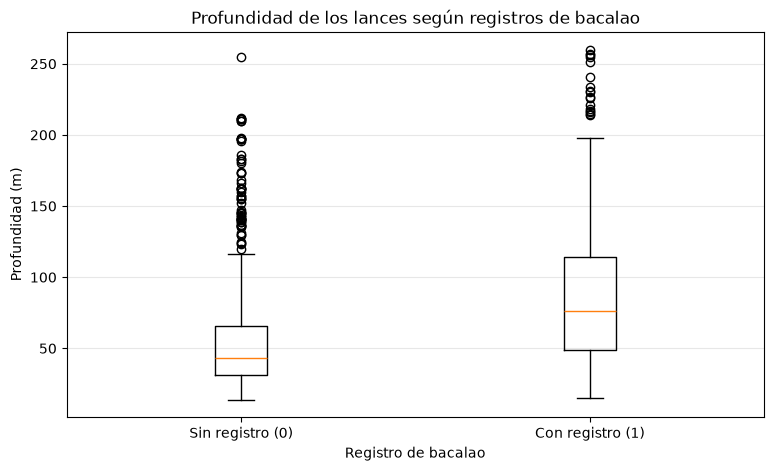

In [29]:
# Separar la profundidad según la variable objetivo
profundidad_sin = df_modelo.loc[
    df_modelo["presencia_bacalao"] == 0, "Depth"
]

profundidad_con = df_modelo.loc[
    df_modelo["presencia_bacalao"] == 1, "Depth"
]

# Crear el gráfico comparativo
plt.figure(figsize=(9, 5))

plt.boxplot(
    [profundidad_sin, profundidad_con],
    tick_labels=["Sin registro (0)", "Con registro (1)"]
)

plt.title("Profundidad de los lances según registros de bacalao")
plt.xlabel("Registro de bacalao")
plt.ylabel("Profundidad (m)")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Comparación de la profundidad según los registros de bacalao

El boxplot comparativo muestra diferencias en la distribución de profundidades entre los lances con y sin registros de *Gadus morhua*.

Los lances con registros de bacalao (clase 1) presentan una mediana de profundidad mayor, aproximadamente 76 metros, frente a los 43 metros de los lances sin registros (clase 0). Además, la clase 1 presenta una mayor dispersión.

Aunque existen diferencias entre ambas distribuciones, también se observa superposición de valores. Por lo tanto, la profundidad no permite distinguir por sí sola ambas clases.

Estos resultados sugieren que la profundidad podría aportar información útil para la clasificación de los lances, aunque su contribución al desempeño predictivo deberá evaluarse posteriormente mediante el modelo de clasificación.

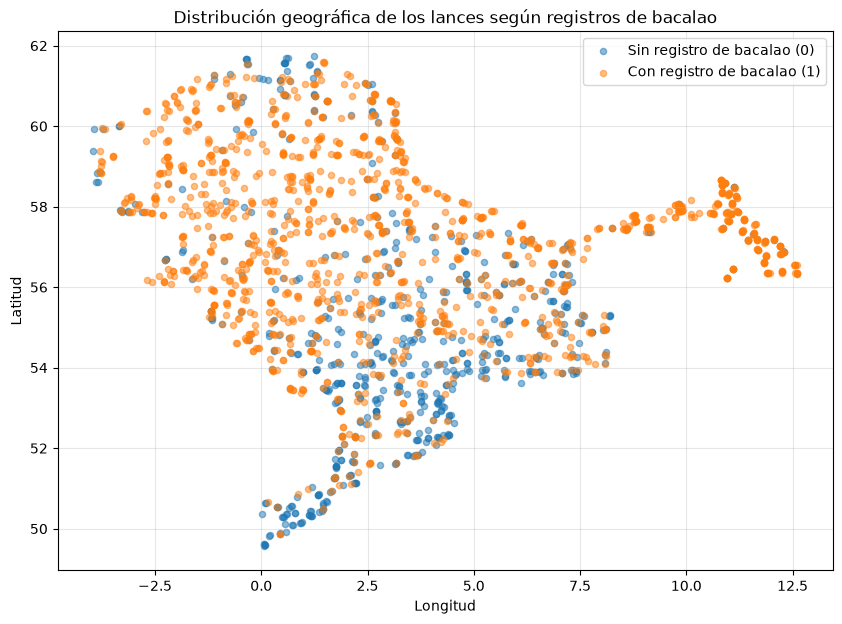

In [30]:
# Separar los lances según la variable objetivo
sin_bacalao = df_modelo[
    df_modelo["presencia_bacalao"] == 0
]

con_bacalao = df_modelo[
    df_modelo["presencia_bacalao"] == 1
]

# Crear gráfico de dispersión geográfica
plt.figure(figsize=(10, 7))

plt.scatter(
    sin_bacalao["ShootLong"],
    sin_bacalao["ShootLat"],
    alpha=0.5,
    s=20,
    label="Sin registro de bacalao (0)"
)

plt.scatter(
    con_bacalao["ShootLong"],
    con_bacalao["ShootLat"],
    alpha=0.5,
    s=20,
    label="Con registro de bacalao (1)"
)

plt.title("Distribución geográfica de los lances según registros de bacalao")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Distribución geográfica de los lances según los registros de bacalao

El gráfico muestra la ubicación de los lances con y sin registros de bacalao del Atlántico.

Se observa que los lances con registros de bacalao (clase 1) aparecen en gran parte del área estudiada, especialmente hacia el norte. En cambio, los lances sin registros (clase 0) se concentran relativamente más hacia el sur.

Aunque ambas clases comparten varias zonas, se observan diferencias geográficas que sugieren que la latitud y la longitud podrían aportar información útil para la clasificación de los lances.

Este análisis representa los registros de los lances estudiados y no permite determinar la distribución real de la especie.


## Preparación del conjunto de datos para el modelado

Se seleccionan las variables predictoras, la variable objetivo y los identificadores de los lances para construir un conjunto de datos organizado, que posteriormente se utilizará para entrenar y evaluar el modelo de clasificación.


In [31]:
# Seleccionar las columnas del dataset procesado
columnas_finales = (
    columnas_id
    + ["Depth", "ShootLat", "ShootLong", "HaulDur"]
    + ["presencia_bacalao"]
)

df_final = df_modelo[columnas_finales].copy()

# Verificar la estructura del dataset
print("Dimensiones del dataset:", df_final.shape)

print("\nTipos de datos:")
print(df_final.dtypes)

print("\nPrimeras cinco observaciones:")
display(df_final.head())

print("\nValores faltantes:")
print(df_final.isnull().sum())

Dimensiones del dataset: (1970, 13)

Tipos de datos:
Survey                   str
Quarter                  str
Year                     str
Country                  str
Ship                     str
Gear                     str
HaulNo                   str
StNo                     str
Depth                  int64
ShootLat             float64
ShootLong            float64
HaulDur                int64
presencia_bacalao      int64
dtype: object

Primeras cinco observaciones:


,Survey,Quarter,Year,Country,Ship,Gear,HaulNo,StNo,Depth,ShootLat,ShootLong,HaulDur,presencia_bacalao
0,NS-IBTS,1,2020,DK,26D4,GOV,1,6,35,56.6076,7.1445,30,0
1,NS-IBTS,1,2020,DK,26D4,GOV,2,8,45,56.5951,6.8874,30,0
2,NS-IBTS,1,2020,DK,26D4,GOV,3,10,33,56.3057,7.1858,30,1
3,NS-IBTS,1,2020,DK,26D4,GOV,4,11,36,56.3333,6.8544,30,0
4,NS-IBTS,1,2020,DK,26D4,GOV,5,19,73,56.7180,2.4918,30,1



Valores faltantes:
Survey               0
Quarter              0
Year                 0
Country              0
Ship                 0
Gear                 0
HaulNo               0
StNo                 0
Depth                0
ShootLat             0
ShootLong            0
HaulDur              0
presencia_bacalao    0
dtype: int64


In [32]:
# Variables disponibles antes de realizar el lance
variables_modelo = ["Depth", "ShootLat", "ShootLong"]

# Variable que queremos predecir
variable_objetivo = "presencia_bacalao"

# Preparar las variables para el modelado
X = df_final[variables_modelo].copy()
y = df_final[variable_objetivo].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nVariables predictoras:")
print(X.columns.tolist())

Dimensiones de X: (1970, 3)
Dimensiones de y: (1970,)

Variables predictoras:
['Depth', 'ShootLat', 'ShootLong']


In [33]:
# Verificar el período y trimestre de los registros
print("Años presentes en el dataset:")
print(sorted(df_final["Year"].unique()))

print("\nTrimestres presentes:")
print(df_final["Quarter"].value_counts().sort_index())

# Cantidad de lances por año y clase
tabla_anual = pd.crosstab(
    df_final["Year"],
    df_final["presencia_bacalao"]
)

tabla_anual.columns = ["Sin registro (0)", "Con registro (1)"]
tabla_anual["Total"] = tabla_anual.sum(axis=1)

print("\nCantidad de lances por año:")
display(tabla_anual)

# Porcentaje de cada clase por año
porcentaje_anual = (
    tabla_anual[["Sin registro (0)", "Con registro (1)"]]
    .div(tabla_anual["Total"], axis=0)
    .mul(100)
    .round(1)
)

print("\nPorcentaje de cada clase por año:")
display(porcentaje_anual)

Años presentes en el dataset:
['2020', '2021', '2022', '2023', '2024', '2025']

Trimestres presentes:
Quarter
1    1970
Name: count, dtype: int64

Cantidad de lances por año:


,Sin registro (0),Con registro (1),Total
Year,,,
2020,118,222,340
2021,121,253,374
2022,80,157,237
2023,87,230,317
2024,107,234,341
2025,122,239,361



Porcentaje de cada clase por año:


,Sin registro (0),Con registro (1)
Year,,
2020,34.7,65.3
2021,32.4,67.6
2022,33.8,66.2
2023,27.4,72.6
2024,31.4,68.6
2025,33.8,66.2


### Distribución de los registros de bacalao por año

Se verificó que los 1.970 lances corresponden al período 2020–2025 y pertenecen al primer trimestre de cada año.

En todos los años predominan los lances con registros de bacalao (clase 1), con porcentajes que varían entre el 65,3 % y el 72,6 %. La mayor proporción se observa en 2023.

La campaña de 2025 contiene 361 lances, de los cuales 239 presentan registros de bacalao (66,2 %) y 122 no registran la especie (33,8 %).

Estos resultados permiten considerar una separación temporal de los datos, utilizando los años 2020–2024 para entrenar los modelos y reservando 2025 para evaluar su desempeño con una campaña posterior.

In [34]:
# Separación temporal de los datos
# Entrenamiento: 2020-2024
# Prueba: 2025

entrenamiento = df_final["Year"].isin(
    ["2020", "2021", "2022", "2023", "2024"]
)

prueba = df_final["Year"] == "2025"

# Separar variables predictoras
X_train = X.loc[entrenamiento].copy()
X_test = X.loc[prueba].copy()

# Separar variable objetivo
y_train = y.loc[entrenamiento].copy()
y_test = y.loc[prueba].copy()

# Verificar dimensiones
print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Entrenamiento:
X_train: (1609, 3)
y_train: (1609,)

Prueba:
X_test: (361, 3)
y_test: (361,)


In [35]:
# Verificar los años de cada conjunto
print("Años de entrenamiento:")
print(sorted(df_final.loc[entrenamiento, "Year"].unique()))

print("\nAños de prueba:")
print(sorted(df_final.loc[prueba, "Year"].unique()))

# Verificar que ningún lance esté en ambos conjuntos
print("\nLances compartidos entre conjuntos:")
print(X_train.index.intersection(X_test.index).size)

# Verificar las clases
print("\nDistribución de clases en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución de clases en prueba:")
print(y_test.value_counts())

Años de entrenamiento:
['2020', '2021', '2022', '2023', '2024']

Años de prueba:
['2025']

Lances compartidos entre conjuntos:
0

Distribución de clases en entrenamiento:
presencia_bacalao
1    1096
0     513
Name: count, dtype: int64

Distribución de clases en prueba:
presencia_bacalao
1    239
0    122
Name: count, dtype: int64


### Separación temporal de los datos para entrenamiento y prueba

Se realizó una separación temporal del conjunto de datos para evaluar la capacidad del modelo de clasificar lances de campañas posteriores.

Se destinaron **1.609 lances correspondientes a 2020–2024 para entrenamiento** y se reservaron **361 lances de 2025 para prueba**.

Se verificó que no existen observaciones compartidas entre ambos conjuntos y que ambos contienen registros de las clases 0 y 1.

Dentro del período 2020–2024 se aplicará validación cruzada temporal para evaluar y ajustar la configuración del modelo, respetando el orden cronológico de las campañas.

La campaña de 2025 se mantendrá como conjunto de prueba independiente y no se utilizará para ajustar hiperparámetros ni seleccionar la configuración del modelo.


### Verificación del conjunto de datos procesado

El conjunto de datos procesado contiene **1.970 observaciones y 13 columnas**, correspondientes a ocho identificadores, cuatro variables numéricas y una variable objetivo.

Se verificó que las variables numéricas no presentan valores faltantes y que cada fila representa un único lance válido.

Para el modelo de clasificación se seleccionaron tres variables predictoras: profundidad (Depth), latitud (ShootLat) y longitud (ShootLong). La duración del lance (HaulDur) se conserva para el análisis exploratorio, pero se excluye del entrenamiento porque no se conoce antes de realizar el muestreo.

De esta manera, se dispone de un conjunto de datos organizado y verificado para desarrollar las etapas de entrenamiento y evaluación.


In [36]:
# Guardar el dataset procesado
ruta_procesado = Path("../data/processed/lances_bacalao_procesado.csv")

df_final.to_csv(ruta_procesado, index=False)

print("Archivo guardado en:", ruta_procesado)
print("Dimensiones:", df_final.shape)

Archivo guardado en: ..\data\processed\lances_bacalao_procesado.csv
Dimensiones: (1970, 13)


### Validación cruzada temporal de la regresión logística

Para evaluar el desempeño de la regresión logística y ajustar sus hiperparámetros, se utiliza validación cruzada temporal con los datos de las campañas de 2020 a 2024.

Se establecen cuatro divisiones, entrenando el modelo con campañas anteriores y validándolo con la campaña siguiente. Este procedimiento permite respetar el orden cronológico de los datos y evitar utilizar información de campañas posteriores durante el entrenamiento.

La campaña de 2025 se mantiene reservada como conjunto de prueba independiente, sin intervenir en la validación cruzada ni en la selección de hiperparámetros.


In [37]:

# Preparar los datos para validación cruzada temporal
df_cv = df_final.loc[entrenamiento].copy()

# Identificar los años disponibles
anios_cv = sorted(df_cv["Year"].unique())

# Crear las cuatro divisiones temporales
divisiones_cv = []

for i in range(1, len(anios_cv)):
    indices_train_cv = df_cv.index[
        df_cv["Year"].isin(anios_cv[:i])
    ]

    indices_val_cv = df_cv.index[
        df_cv["Year"] == anios_cv[i]
    ]

    posiciones_train_cv = df_cv.index.get_indexer(indices_train_cv)
    posiciones_val_cv = df_cv.index.get_indexer(indices_val_cv)

    divisiones_cv.append(
        (posiciones_train_cv, posiciones_val_cv)
    )

# Mostrar las divisiones
for i in range(1, len(anios_cv)):
    print(
        f"Entrenamiento: {anios_cv[:i]} "
        f"→ Validación: {anios_cv[i]}"
    )

print("\nCantidad de divisiones:", len(divisiones_cv))


# Variables predictoras y objetivo para la validación cruzada
X_cv = df_cv[["Depth", "ShootLat", "ShootLong"]].copy()
y_cv = df_cv["presencia_bacalao"].copy()

print("Dimensiones de X_cv:", X_cv.shape)
print("Dimensiones de y_cv:", y_cv.shape)



Entrenamiento: ['2020'] → Validación: 2021
Entrenamiento: ['2020', '2021'] → Validación: 2022
Entrenamiento: ['2020', '2021', '2022'] → Validación: 2023
Entrenamiento: ['2020', '2021', '2022', '2023'] → Validación: 2024

Cantidad de divisiones: 4
Dimensiones de X_cv: (1609, 3)
Dimensiones de y_cv: (1609,)


In [38]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Regresión logística inicial con C = 1
modelo_logistico_cv = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", LogisticRegression(
        C=1,
        max_iter=1000,
        random_state=42
    ))
])

# Métricas de evaluación
metricas_cv = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# Validación cruzada temporal
resultados_logistico_cv = cross_validate(
    modelo_logistico_cv,
    X_cv,
    y_cv,
    cv=divisiones_cv,
    scoring=metricas_cv
)

# Resultados por campaña
tabla_logistico_cv = pd.DataFrame({
    "Año de validación": anios_cv[1:],
    "Accuracy": resultados_logistico_cv["test_accuracy"],
    "Precision": resultados_logistico_cv["test_precision"],
    "Recall": resultados_logistico_cv["test_recall"],
    "F1-score": resultados_logistico_cv["test_f1"]
})

display(tabla_logistico_cv.round(3))

print("\nPromedio de las métricas:")
display(
    tabla_logistico_cv[
        ["Accuracy", "Precision", "Recall", "F1-score"]
    ].mean().round(3)
)


,Año de validación,Accuracy,Precision,Recall,F1-score
0,2021,0.762,0.763,0.941,0.842
1,2022,0.751,0.795,0.841,0.817
2,2023,0.751,0.813,0.852,0.832
3,2024,0.754,0.764,0.927,0.838



Promedio de las métricas:


Accuracy     0.754
Precision    0.784
Recall       0.890
F1-score     0.832
dtype: float64

In [39]:

from sklearn.dummy import DummyClassifier

# Modelo de referencia: predice la clase mayoritaria
modelo_baseline_cv = DummyClassifier(
    strategy="most_frequent"
)

# Evaluación con las mismas divisiones temporales
resultados_baseline_cv = cross_validate(
    modelo_baseline_cv,
    X_cv,
    y_cv,
    cv=divisiones_cv,
    scoring=metricas_cv
)

# Comparación de métricas promedio
comparacion_baseline_cv = pd.DataFrame({
    "Regresión logística": [
        resultados_logistico_cv["test_accuracy"].mean(),
        resultados_logistico_cv["test_precision"].mean(),
        resultados_logistico_cv["test_recall"].mean(),
        resultados_logistico_cv["test_f1"].mean()
    ],
    "Baseline": [
        resultados_baseline_cv["test_accuracy"].mean(),
        resultados_baseline_cv["test_precision"].mean(),
        resultados_baseline_cv["test_recall"].mean(),
        resultados_baseline_cv["test_f1"].mean()
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])

display(comparacion_baseline_cv.round(3))


,Regresión logística,Baseline
Accuracy,0.754,0.688
Precision,0.784,0.688
Recall,0.890,1.000
F1-score,0.832,0.815


### Ajuste de hiperparámetros de la regresión logística

Se evaluaron cinco valores del parámetro de regularización C mediante GridSearchCV, utilizando las cuatro divisiones temporales establecidas con las campañas de 2020 a 2024.

Se utilizó el F1-score como criterio principal para comparar las configuraciones, considerando el equilibrio entre precision y recall en la identificación de lances con registros de bacalao.



In [40]:

from sklearn.model_selection import GridSearchCV

# Valores de C utilizados en la experimentación original
parametros_logistico_cv = {
    "clasificador__C": [0.01, 0.1, 1, 10, 100]
}

# Búsqueda de hiperparámetros con validación temporal
busqueda_logistico_cv = GridSearchCV(
    estimator=modelo_logistico_cv,
    param_grid=parametros_logistico_cv,
    scoring="f1",
    cv=divisiones_cv,
    refit=True
)

# Ajustar utilizando exclusivamente campañas 2020-2024
busqueda_logistico_cv.fit(X_cv, y_cv)

print("Mejor valor de C:")
print(busqueda_logistico_cv.best_params_)

print("\nMejor F1-score promedio:")
print(round(busqueda_logistico_cv.best_score_, 3))

# Resultados de todos los valores evaluados
tabla_parametros_cv = pd.DataFrame({
    "Valor de C": busqueda_logistico_cv.cv_results_[
        "param_clasificador__C"
    ],
    "F1-score promedio": busqueda_logistico_cv.cv_results_[
        "mean_test_score"
    ]
})

display(tabla_parametros_cv.round(3))


Mejor valor de C:
{'clasificador__C': 0.01}

Mejor F1-score promedio:
0.834


,Valor de C,F1-score promedio
0,0.01,0.834
1,0.10,0.834
2,1.00,0.832
3,10.00,0.834
4,100.00,0.834



### Interpretación del ajuste de hiperparámetros

La búsqueda de hiperparámetros mediante GridSearchCV permitió comparar cinco valores del parámetro C de la regresión logística, utilizando validación cruzada temporal con las campañas de 2020 a 2024.

La configuración con C = 0.01 obtuvo el mayor F1-score promedio, aproximadamente 0.834. Sin embargo, la configuración inicial con C = 1 alcanzó un F1-score promedio de 0.832, con una diferencia de apenas 0.002.

Dado que la mejora observada fue pequeña, se decidió conservar C = 1 para el modelo final, priorizando una configuración de referencia que presentó un desempeño comparable durante la validación temporal.

La selección se realizó sin utilizar la campaña de 2025, que se mantuvo reservada para la evaluación independiente.



### Selección del modelo de clasificación

Durante la etapa de experimentación se compararon tres algoritmos de clasificación supervisada: regresión logística, K-Nearest Neighbors (KNN) y árbol de decisión.

Los mejores resultados obtenidos después del ajuste de hiperparámetros fueron:

| Algoritmo | F1-score promedio |
|---|---:|
| Regresión logística | 0.834 |
| Árbol de decisión | 0.828 |
| K-Nearest Neighbors (KNN) | 0.822 |

La regresión logística presentó el mayor F1-score promedio entre los algoritmos evaluados, por lo que se seleccionó como modelo final. Esta decisión se fundamentó en los resultados obtenidos mediante validación cruzada temporal, considerando el equilibrio entre precisión y recall para la identificación de lances con registros de bacalao.



### Funcionamiento del modelo de regresión logística

La regresión logística es un algoritmo de clasificación supervisada que permite estimar la probabilidad de que un registro pertenezca a una de dos clases.

En este proyecto, el modelo utiliza tres variables predictoras: profundidad (Depth), latitud (ShootLat) y longitud (ShootLong).

Durante el entrenamiento con los datos de 2020 a 2024, el algoritmo aprende cómo se relacionan estas variables con los registros de bacalao. Para realizar una predicción, primero estandariza los valores y luego los combina mediante cálculos matemáticos que permiten obtener una probabilidad estimada entre 0 y 1.

A partir de esa probabilidad, el modelo aplica un umbral de decisión de 0.50:

- **Clase 0:** probabilidad inferior a 0.50, que indica un lance sin registro de bacalao.
- **Clase 1:** probabilidad igual o superior a 0.50, que indica un lance con registro de bacalao.

Una vez entrenado, el modelo puede utilizar las variables predictoras de nuevos lances para estimar la probabilidad de registrar bacalao del Atlántico y asignar una clase según el umbral de decisión establecido.

Es importante aclarar que el modelo predice la presencia de registros de bacalao en los lances de investigación, pero no determina la presencia o ausencia real de la especie en una zona marítima.


### Entrenamiento del modelo: Regresión logística

Se seleccionó la regresión logística para estimar la probabilidad de registrar bacalao del Atlántico en futuros lances de investigación pesquera.

Se utilizarán tres variables predictoras: profundidad ("Depth"), latitud ("ShootLat") y longitud ("ShootLong").

Las variables se estandarizarán mediante StandardScaler, incorporado en un Pipeline para evitar fugas de información.

Se utilizará el parámetro de regularización C = 1. El modelo se entrenará con las campañas de 2020 a 2024 y se evaluará con la campaña de 2025, reservada como conjunto de prueba.

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Crear el modelo final de regresión logística
modelo_final = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", LogisticRegression(
        C=1,
        max_iter=1000,
        random_state=42
    ))
])

# Entrenar con los datos de 2020-2024
modelo_final.fit(X_train, y_train)

print("Modelo entrenado correctamente")
print("Cantidad de lances:", len(X_train))
print("Variables utilizadas:", X_train.columns.tolist())

Modelo entrenado correctamente
Cantidad de lances: 1609
Variables utilizadas: ['Depth', 'ShootLat', 'ShootLong']



### Guardado del modelo entrenado para su reutilización

Una vez entrenado el modelo final de regresión logística con los datos de 2020–2024, se guarda el Pipeline completo utilizando la biblioteca joblib.

El archivo se almacena en la carpeta models/ de la estructura Cookiecutter e incluye tanto la estandarización mediante StandardScaler como el clasificador entrenado.

Esto permite reutilizar el modelo para realizar predicciones sobre nuevos datos sin necesidad de repetir el entrenamiento. El guardado no modifica los parámetros ni los resultados de las evaluaciones realizadas.


In [42]:

import joblib
from pathlib import Path

# Carpeta para guardar el modelo entrenado
ruta_modelos = Path("../models")
ruta_modelos.mkdir(parents=True, exist_ok=True)

# Nombre del archivo
ruta_modelo = ruta_modelos / "modelo_logistico_bacalao.joblib"

# Guardar el Pipeline completo
joblib.dump(modelo_final, ruta_modelo)

print("Modelo guardado correctamente")
print("Ubicación:", ruta_modelo.resolve())


Modelo guardado correctamente
Ubicación: C:\Users\veneg\Documents\Proyectos\clasificacion-bacalao-atlantico\models\modelo_logistico_bacalao.joblib


## Evaluación del modelo final

Para evaluar el desempeño de la regresión logística, se utilizarán los 361 lances correspondientes a la campaña de 2025, que se mantuvieron separados de los datos de entrenamiento.

Se calcularán las métricas accuracy, precision, recall y F1-score para analizar la capacidad del modelo de clasificar los lances con y sin registros de bacalao del Atlántico.

In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Realizar predicciones sobre la campaña de 2025
y_pred = modelo_final.predict(X_test)

# Calcular las métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Resultados del modelo en 2025:")
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score: {f1:.3f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Sin registro (0)", "Con registro (1)"],
    zero_division=0
))

Resultados del modelo en 2025:
Accuracy:  0.759
Precision: 0.752
Recall:    0.950
F1-score: 0.839

Reporte de clasificación:
                  precision    recall  f1-score   support

Sin registro (0)       0.80      0.39      0.52       122
Con registro (1)       0.75      0.95      0.84       239

        accuracy                           0.76       361
       macro avg       0.77      0.67      0.68       361
    weighted avg       0.77      0.76      0.73       361



### Matriz de confusión del modelo final

Se construirá una matriz de confusión para analizar los aciertos y errores de clasificación del modelo en la campaña de 2025.

Esta matriz permitirá identificar cuántos lances con y sin registros de bacalao fueron clasificados correctamente, así como los falsos positivos y falsos negativos.

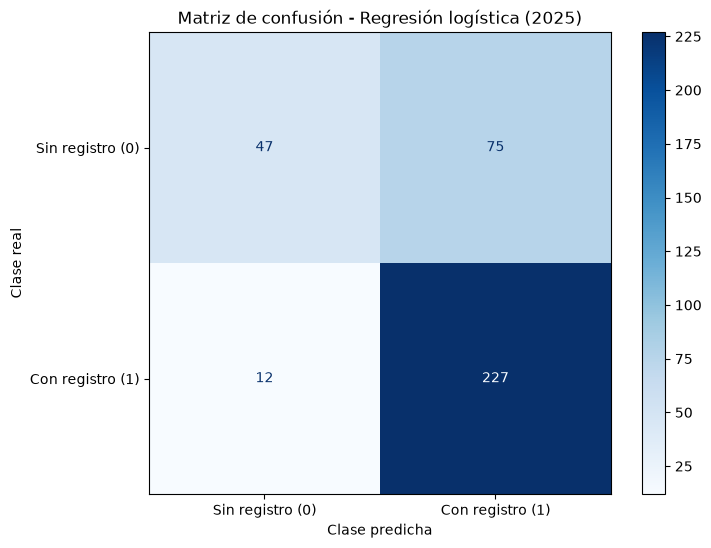

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcular la matriz de confusión
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Mostrar la matriz
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sin registro (0)", "Con registro (1)"]
)

fig, ax = plt.subplots(figsize=(8, 6))
visualizacion.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Matriz de confusión - Regresión logística (2025)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.show()

### Interpretación de los resultados del modelo final

La regresión logística se evaluó utilizando los 361 lances de la campaña de 2025, que no participaron del entrenamiento.

El modelo alcanzó un accuracy de 0,759 y un F1-score de 0,839 para la clase positiva (lances con registros de bacalao). Además, obtuvo una precisión de 0,752 y un recall de 0,950 para esta clase.

La matriz de confusión muestra que se clasificaron correctamente 274 lances: 227 con registros de bacalao y 47 sin registros. Se identificaron 75 falsos positivos y 12 falsos negativos.

Estos resultados evidencian que el modelo presenta una alta capacidad para identificar lances con registros de bacalao, pero mayores dificultades para reconocer aquellos sin registros, cuyo recall fue de 0,39.

Esta diferencia debe considerarse al interpretar el desempeño general, ya que existe un desequilibrio entre las clases y el modelo presenta una tendencia a clasificar los lances como positivos, lo que incrementa los falsos positivos.

Por lo tanto, la regresión logística permite identificar patrones asociados con los registros de bacalao a partir de la profundidad y la ubicación geográfica, aunque presenta limitaciones para distinguir ambas clases con la misma eficacia. Las predicciones se refieren a registros de la especie durante los lances y no permiten afirmar su presencia o ausencia real en una zona.

## Evaluación adicional del modelo con datos preliminares de 2026

Con el propósito de analizar la capacidad de generalización del modelo frente a una campaña posterior, se realizará una evaluación exploratoria utilizando datos de la campaña NS-IBTS, correspondiente al primer trimestre de 2026, obtenidos de ICES-DATRAS.

Para garantizar la comparabilidad con el conjunto de datos original, se aplicarán los mismos criterios de preparación y validación utilizados en las campañas de 2020 a 2025. El procedimiento incluirá la identificación de los registros HH y HL, la selección de lances válidos, la verificación de la información biológica y la construcción de la variable objetivo presencia_bacalao.

Posteriormente, se seleccionarán las mismas variables predictoras (Depth, ShootLat y ShootLong) y se utilizará el modelo final de regresión logística, previamente entrenado con las campañas de 2020 a 2024, para generar predicciones sobre los datos de 2026, sin modificar sus parámetros ni realizar un nuevo entrenamiento.

El desempeño se evaluará mediante accuracy, precision, recall, F1-score y matriz de confusión. Los resultados se compararán con los obtenidos en la evaluación principal de 2025, con el objetivo de identificar posibles diferencias en el comportamiento del modelo.

**Consideración metodológica:** ICES-DATRAS identifica los datos de 2026 como preliminares. Por lo tanto, esta evaluación tendrá carácter exploratorio y complementario, y sus resultados deberán interpretarse con cautela.


### Exploración inicial del dataset de 2026

Se carga el archivo original de ICES-DATRAS y se identifican los registros HH (información general de los lances) y HL (información biológica de las especies).

Esta separación permitirá analizar la validez de los lances y construir posteriormente el conjunto de evaluación.

In [45]:

import csv
from pathlib import Path

# Ubicar el archivo original de la campaña 2026
ruta_csv_2026 = Path("../data/raw/datras_ns_ibts_2026_original.csv")

print("¿Existe el archivo?", ruta_csv_2026.exists())

# Separar los registros HH y HL
registros_hh_2026 = []
registros_hl_2026 = []
encabezados_hh_2026 = None
encabezados_hl_2026 = None

with open(ruta_csv_2026, "r", encoding="utf-8-sig", newline="") as archivo:
    lector = csv.reader(archivo)

    for fila in lector:
        if not fila:
            continue

        if fila[0] == "RecordType":
            if "HaulDur" in fila:
                encabezados_hh_2026 = fila
            elif "ScientificName_WoRMS" in fila:
                encabezados_hl_2026 = fila

        elif fila[0] == "HH":
            registros_hh_2026.append(fila)

        elif fila[0] == "HL":
            registros_hl_2026.append(fila)

# Crear las tablas
df_hh_2026 = pd.DataFrame(registros_hh_2026, columns=encabezados_hh_2026)
df_hl_2026 = pd.DataFrame(registros_hl_2026, columns=encabezados_hl_2026)

print("\nDimensiones de las tablas:")
print("HH:", df_hh_2026.shape)
print("HL:", df_hl_2026.shape)

display(df_hh_2026.head())
display(df_hl_2026.head())


¿Existe el archivo? True

Dimensiones de las tablas:
HH: (331, 71)
HL: (48069, 30)


,RecordType,Survey,Quarter,Country,Ship,Gear,SweepLngt,GearEx,DoorType,StNo,...,SecchiDepth,Turbidity,TidePhase,TideSpeed,PelSampType,MinTrawlDepth,MaxTrawlDepth,SurveyIndexArea,ReasonHaulDisruption,DateofCalculation
0,HH,NS-IBTS,1,FR,35HT,GOV,50,-9,P,E2000,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20261030
1,HH,NS-IBTS,1,FR,35HT,GOV,50,-9,P,E2001,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20261030
2,HH,NS-IBTS,1,FR,35HT,GOV,50,-9,P,E2002,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20261030
3,HH,NS-IBTS,1,FR,35HT,GOV,50,-9,P,E2003,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20261030
4,HH,NS-IBTS,1,FR,35HT,GOV,50,-9,P,E2009,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20261030


,RecordType,Survey,Quarter,Country,Ship,Gear,SweepLngt,GearEx,DoorType,StNo,...,SubWgt,CatCatchWgt,LngtCode,LngtClass,HLNoAtLngt,DevStage,LenMeasType,ValidAphiaID,ScientificName_WoRMS,DateofCalculation
0,HL,NS-IBTS,1,DE,26D4,GOV,50,-9,P,1,...,-9,1356,0,55,6.00,-9,1,126425,Sprattus sprattus,20261030
1,HL,NS-IBTS,1,DE,26D4,GOV,50,-9,P,1,...,-9,1356,0,60,14.00,-9,1,126425,Sprattus sprattus,20261030
2,HL,NS-IBTS,1,DE,26D4,GOV,50,-9,P,1,...,-9,1356,0,65,16.00,-9,1,126425,Sprattus sprattus,20261030
3,HL,NS-IBTS,1,DE,26D4,GOV,50,-9,P,1,...,-9,1356,0,70,8.00,-9,1,126425,Sprattus sprattus,20261030
4,HL,NS-IBTS,1,DE,26D4,GOV,50,-9,P,1,...,-9,1356,0,75,8.00,-9,1,126425,Sprattus sprattus,20261030



### Identificación de los registros de la campaña 2026

El archivo descargado de ICES-DATRAS contiene 331 registros de cabecera de lance (HH), con 71 columnas, y 48.069 registros biológicos (HL), con 30 columnas.

La tabla HH proporciona información sobre las características de los lances, como su ubicación geográfica, profundidad y códigos de validez. La tabla HL contiene los registros biológicos de las especies identificadas durante los muestreos.

Esta estructura es equivalente a la utilizada en el conjunto de datos original de 2020–2025, lo que permite aplicar los mismos procedimientos de preparación y validación.

Antes de realizar predicciones, será necesario identificar los lances válidos y comprobar la disponibilidad de información biológica asociada.


In [46]:

# Revisar los códigos de validez de los lances de 2026
print("Distribución de códigos de validez:")
print(df_hh_2026["HaulVal"].value_counts(dropna=False))

# Seleccionar únicamente los lances válidos
df_validos_2026 = df_hh_2026[
    df_hh_2026["HaulVal"] == "V"
].copy()

print("\nCantidad de lances válidos:")
print(len(df_validos_2026))

# Verificar el año y trimestre
print("\nAños:")
print(df_validos_2026["Year"].value_counts())

print("\nTrimestres:")
print(df_validos_2026["Quarter"].value_counts())


Distribución de códigos de validez:
HaulVal
V    324
I      7
Name: count, dtype: int64

Cantidad de lances válidos:
324

Años:
Year
2026    324
Name: count, dtype: int64

Trimestres:
Quarter
1    324
Name: count, dtype: int64



### Selección de los lances válidos de 2026

Se analizaron los códigos de validez de los 331 lances registrados en la campaña NS-IBTS del primer trimestre de 2026.

Se identificaron 324 lances válidos (HaulVal = V) y 7 lances inválidos (HaulVal = I). Para mantener la coherencia con el procedimiento aplicado al dataset de 2020–2025, se seleccionaron únicamente los lances válidos.

También se verificó que todos los registros seleccionados corresponden al año 2026 y al primer trimestre.

Esta selección constituye el primer control de calidad para preparar el conjunto de evaluación. Posteriormente, se comprobará que los lances tengan información biológica asociada.


In [47]:

# Columnas que identifican cada lance
columnas_id_2026 = [
    "Survey", "Quarter", "Year",
    "Country", "Ship", "Gear", "HaulNo", "StNo"
]

# Verificar que cada lance válido sea único
print("Duplicados entre los lances válidos:")
print(df_validos_2026.duplicated(subset=columnas_id_2026).sum())

# Identificar los lances con registros biológicos
lances_hl_2026 = df_hl_2026[
    columnas_id_2026
].drop_duplicates()

# Comprobar correspondencia HH-HL
control_biologico_2026 = df_validos_2026.merge(
    lances_hl_2026,
    on=columnas_id_2026,
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("\nCorrespondencia con la tabla HL:")
print(control_biologico_2026["_merge"].value_counts())

# Revisar los códigos de registro de especies
print("\nCódigos de especies estándar:")
print(df_validos_2026["StdSpecRecCode"].value_counts(dropna=False))

print("\nCódigos de especies acompañantes:")
print(df_validos_2026["BySpecRecCode"].value_counts(dropna=False))


Duplicados entre los lances válidos:
0

Correspondencia con la tabla HL:
_merge
both          324
left_only       0
right_only      0
Name: count, dtype: int64

Códigos de especies estándar:
StdSpecRecCode
1    324
Name: count, dtype: int64

Códigos de especies acompañantes:
BySpecRecCode
1    324
Name: count, dtype: int64



### Verificación de la información biológica de 2026

Se comprobó que los 324 lances válidos presentan identificadores únicos y cuentan con registros asociados en la tabla biológica HL, sin detectarse lances duplicados ni registros HH válidos sin correspondencia biológica.

Además, todos los lances presentan los códigos StdSpecRecCode = 1 y BySpecRecCode = 1, de acuerdo con los criterios de registro de especies utilizados en el análisis original de ICES-DATRAS.

Estos resultados permiten continuar con la identificación de los lances con y sin registros válidos de bacalao del Atlántico.

La verificación es especialmente importante para fundamentar la construcción de la clase 0, que representará la falta de registros documentados de la especie durante un lance válido, sin asumir su ausencia real en la zona estudiada.


In [48]:

# Seleccionar los registros biológicos de bacalao del Atlántico
df_bacalao_2026 = df_hl_2026[
    df_hl_2026["ScientificName_WoRMS"] == "Gadus morhua"
].copy()

print("Registros biológicos de bacalao:")
print(len(df_bacalao_2026))

# Revisar la validez de los registros biológicos
print("\nCódigos SpecVal de bacalao:")
print(df_bacalao_2026["SpecVal"].value_counts(dropna=False))

# Seleccionar registros biológicos válidos
bacalao_valido_2026 = df_bacalao_2026[
    df_bacalao_2026["SpecVal"] == "1"
][columnas_id_2026].drop_duplicates()

# Identificar los lances válidos con registros de bacalao
lances_con_bacalao_2026 = df_validos_2026[
    columnas_id_2026
].merge(
    bacalao_valido_2026,
    on=columnas_id_2026,
    how="inner",
    validate="one_to_one"
)

# Calcular la cantidad de lances por clase
cantidad_con_2026 = len(lances_con_bacalao_2026)
cantidad_sin_2026 = len(df_validos_2026) - cantidad_con_2026

print("\nLances con registros de bacalao (clase 1):", cantidad_con_2026)
print("Lances sin registros de bacalao (clase 0):", cantidad_sin_2026)

print("\nPorcentaje por clase:")
print("Clase 1:", round(cantidad_con_2026 / len(df_validos_2026) * 100, 1), "%")
print("Clase 0:", round(cantidad_sin_2026 / len(df_validos_2026) * 100, 1), "%")


Registros biológicos de bacalao:
967

Códigos SpecVal de bacalao:
SpecVal
1    967
Name: count, dtype: int64

Lances con registros de bacalao (clase 1): 219
Lances sin registros de bacalao (clase 0): 105

Porcentaje por clase:
Clase 1: 67.6 %
Clase 0: 32.4 %



### Identificación de los lances con y sin registros de bacalao en 2026

Se identificaron 967 registros biológicos válidos de *Gadus morhua* (SpecVal = 1), correspondientes a 219 lances con registros de bacalao (67,6 %). Los 105 lances restantes (32,4 %) no presentaron registros de la especie. Un mismo lance puede contener varios registros biológicos.

Para construir la variable objetivo presencia_bacalao, se asignará la clase 1 a los lances con registros válidos de bacalao y la clase 0 a aquellos sin registros, considerando los controles de validez e información biológica realizados previamente.

La clase 0 representa la falta de detección documentada durante el muestreo, sin implicar la ausencia real de la especie en la zona.


In [49]:

import numpy as np

# Crear una copia de los lances válidos
df_evaluacion_2026 = df_validos_2026.copy()

# Incorporar los registros válidos de bacalao
df_evaluacion_2026 = df_evaluacion_2026.merge(
    bacalao_valido_2026.assign(presencia_bacalao=1),
    on=columnas_id_2026,
    how="left",
    validate="one_to_one"
)

# Asignar clase 0 a los lances sin registros de bacalao
df_evaluacion_2026["presencia_bacalao"] = (
    df_evaluacion_2026["presencia_bacalao"]
    .fillna(0)
    .astype(int)
)

# Variables predictoras del modelo final
variables_2026 = ["Depth", "ShootLat", "ShootLong"]

# Convertir a formato numérico
for columna in variables_2026:
    df_evaluacion_2026[columna] = pd.to_numeric(
        df_evaluacion_2026[columna],
        errors="coerce"
    )

# Tratar el código de valores faltantes de ICES-DATRAS
df_evaluacion_2026[variables_2026] = (
    df_evaluacion_2026[variables_2026]
    .replace(-9, np.nan)
)

# Verificar el conjunto de evaluación
print("Dimensiones:", df_evaluacion_2026.shape)

print("\nDistribución de clases:")
print(df_evaluacion_2026["presencia_bacalao"].value_counts())

print("\nValores faltantes:")
print(df_evaluacion_2026[variables_2026].isna().sum())

print("\nDuplicados por lance:")
print(df_evaluacion_2026.duplicated(subset=columnas_id_2026).sum())

# Mostrar las columnas relevantes
display(
    df_evaluacion_2026[
        columnas_id_2026 + variables_2026 + ["presencia_bacalao"]
    ].head()
)


Dimensiones: (324, 72)

Distribución de clases:
presencia_bacalao
1    219
0    105
Name: count, dtype: int64

Valores faltantes:
Depth        0
ShootLat     0
ShootLong    0
dtype: int64

Duplicados por lance:
0


,Survey,Quarter,Year,Country,Ship,Gear,HaulNo,StNo,Depth,ShootLat,ShootLong,presencia_bacalao
0,NS-IBTS,1,2026,FR,35HT,GOV,1,E2001,27,50.5981,1.5221,0
1,NS-IBTS,1,2026,FR,35HT,GOV,2,E2002,30,50.3049,1.1739,0
2,NS-IBTS,1,2026,FR,35HT,GOV,3,E2003,45,50.4331,1.1577,0
3,NS-IBTS,1,2026,FR,35HT,GOV,4,E2009,34,50.1557,0.9691,0
4,NS-IBTS,1,2026,FR,35HT,GOV,5,E2010,31,49.8742,0.4022,0



### Preparación del conjunto de evaluación de 2026

Se construyó un conjunto de 324 lances válidos, con 219 observaciones de clase 1 y 105 de clase 0.

Se convirtieron a formato numérico las variables Depth, ShootLat y ShootLong, y se verificó que no presentan valores faltantes. Tampoco se identificaron lances duplicados.

Estos controles permiten utilizar el conjunto de 2026 para evaluar el modelo previamente entrenado, manteniendo los mismos criterios de preparación aplicados al dataset original.


In [50]:

# Seleccionar las variables predictoras y la variable objetivo
X_2026 = df_evaluacion_2026[
    ["Depth", "ShootLat", "ShootLong"]
].copy()

y_2026 = df_evaluacion_2026["presencia_bacalao"].copy()

# Aplicar el modelo final sin volver a entrenarlo
predicciones_2026 = modelo_final.predict(X_2026)

# Calcular las probabilidades estimadas de la clase 1
probabilidades_2026 = modelo_final.predict_proba(X_2026)[:, 1]

# Organizar los resultados
resultados_2026 = X_2026.copy()
resultados_2026["Registro real"] = y_2026
resultados_2026["Predicción"] = predicciones_2026
resultados_2026["Probabilidad de registro"] = probabilidades_2026.round(3)

print("Cantidad de predicciones:", len(predicciones_2026))

print("\nDistribución de las predicciones:")
print(resultados_2026["Predicción"].value_counts())

print("\nPrimeras diez predicciones:")
display(resultados_2026.head(10))


Cantidad de predicciones: 324

Distribución de las predicciones:
Predicción
1    266
0     58
Name: count, dtype: int64

Primeras diez predicciones:


,Depth,ShootLat,ShootLong,Registro real,Predicción,Probabilidad de registro
0,27,50.5981,1.5221,0,0,0.221
1,30,50.3049,1.1739,0,0,0.205
2,45,50.4331,1.1577,0,0,0.222
3,34,50.1557,0.9691,0,0,0.199
4,31,49.8742,0.4022,0,0,0.180
5,24,49.6198,0.0569,0,0,0.163
6,42,50.3873,0.8030,0,0,0.216
7,47,50.5618,0.7320,0,0,0.229
8,48,50.6314,0.0911,0,0,0.230
9,25,51.0439,1.1812,1,0,0.244



### Evaluación del desempeño del modelo con datos de 2026

Se compararán las predicciones obtenidas con los registros reales de la campaña 2026 mediante las métricas accuracy, precision, recall y F1-score.

También se analizará la matriz de confusión para identificar los aciertos y errores del modelo en ambas clases.


In [51]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calcular las métricas de evaluación
accuracy_2026 = accuracy_score(y_2026, predicciones_2026)
precision_2026 = precision_score(y_2026, predicciones_2026)
recall_2026 = recall_score(y_2026, predicciones_2026)
f1_2026 = f1_score(y_2026, predicciones_2026)

print("Métricas de evaluación - Campaña 2026")
print(f"Accuracy:  {accuracy_2026:.3f}")
print(f"Precision: {precision_2026:.3f}")
print(f"Recall:    {recall_2026:.3f}")
print(f"F1-score:  {f1_2026:.3f}")

# Calcular matriz de confusión
matriz_2026 = confusion_matrix(
    y_2026,
    predicciones_2026,
    labels=[0, 1]
)

print("\nMatriz de confusión:")
print(matriz_2026)

# Mostrar métricas por clase
print("\nReporte de clasificación:")
print(classification_report(
    y_2026,
    predicciones_2026,
    target_names=["Sin registro (0)", "Con registro (1)"],
    digits=3
))


Métricas de evaluación - Campaña 2026
Accuracy:  0.738
Precision: 0.752
Recall:    0.913
F1-score:  0.825

Matriz de confusión:
[[ 39  66]
 [ 19 200]]

Reporte de clasificación:
                  precision    recall  f1-score   support

Sin registro (0)      0.672     0.371     0.479       105
Con registro (1)      0.752     0.913     0.825       219

        accuracy                          0.738       324
       macro avg      0.712     0.642     0.652       324
    weighted avg      0.726     0.738     0.713       324




### Matriz de confusión de la campaña 2026

La matriz de confusión permite visualizar los aciertos y errores del modelo en la clasificación de los lances con y sin registros de bacalao del Atlántico.


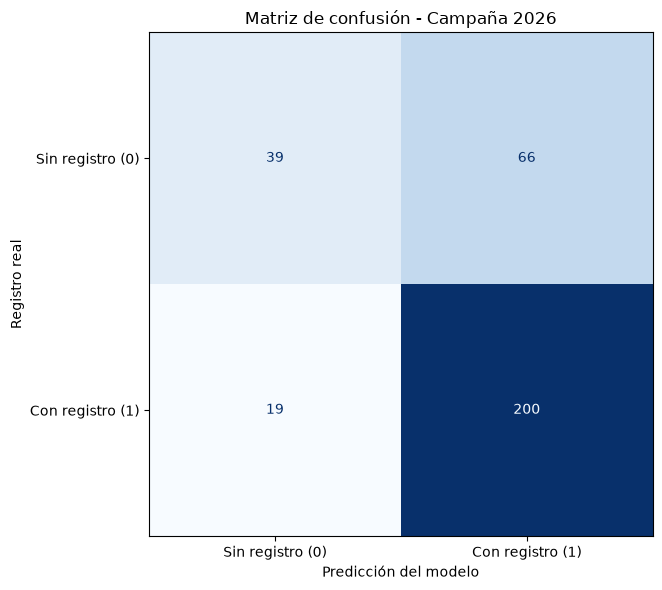

In [52]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Visualizar la matriz de confusión de 2026
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_2026,
    display_labels=["Sin registro (0)", "Con registro (1)"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Matriz de confusión - Campaña 2026")
plt.xlabel("Predicción del modelo")
plt.ylabel("Registro real")
plt.tight_layout()
plt.show()



### Interpretación de los resultados de 2026

El modelo de regresión logística se evaluó utilizando 324 lances válidos de la campaña 2026, sin modificar el entrenamiento realizado con datos de 2020 a 2024.

Se obtuvo una exactitud (accuracy) de 0,738, una precisión de 0,752, un recall de 0,913 y un F1-score de 0,825 para la clase positiva, correspondiente a los lances con registros de bacalao.

La matriz de confusión mostró 239 clasificaciones correctas: 200 lances con registros de bacalao y 39 sin registros. También se identificaron 66 falsos positivos y 19 falsos negativos.

Estos resultados evidencian una elevada capacidad para identificar lances con registros de bacalao, con un recall del 91,3 %. Sin embargo, el modelo reconoció correctamente solo el 37,1 % de los lances sin registros, lo que demuestra un desempeño desigual entre ambas clases.

Esta diferencia indica una tendencia a favorecer las predicciones positivas y constituye una limitación importante del modelo. Por lo tanto, aunque permite identificar patrones asociados con los registros de bacalao, sus predicciones deben interpretarse con precaución y no permiten afirmar la presencia o ausencia real de la especie en una zona.



### Comparación del desempeño del modelo entre 2025 y 2026

Se comparan los resultados de la evaluación principal de 2025 y la evaluación exploratoria de 2026 para analizar la capacidad de generalización temporal del modelo y reconocer posibles diferencias en su desempeño.


In [53]:

# Calcular las métricas de ambas campañas
# Utilizamos las predicciones ya obtenidas con el modelo final

metricas_2025 = [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred),
    recall_score(y_test, y_pred),
    f1_score(y_test, y_pred)
]

metricas_2026 = [
    accuracy_2026,
    precision_2026,
    recall_2026,
    f1_2026
]

# Construir tabla comparativa
comparacion_campanas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-score"],
    "2025": metricas_2025,
    "2026": metricas_2026
})

comparacion_campanas["Diferencia (2026 - 2025)"] = (
    comparacion_campanas["2026"] - comparacion_campanas["2025"]
)

display(comparacion_campanas.round(3))


,Métrica,2025,2026,Diferencia (2026 - 2025)
0,Accuracy,0.759,0.738,-0.021
1,Precision,0.752,0.752,0.000
2,Recall,0.950,0.913,-0.037
3,F1-score,0.839,0.825,-0.014


### Comparación gráfica del desempeño del modelo en 2025 y 2026

El siguiente gráfico permite comparar visualmente las métricas obtenidas en la evaluación principal de 2025 y en la evaluación adicional de 2026.

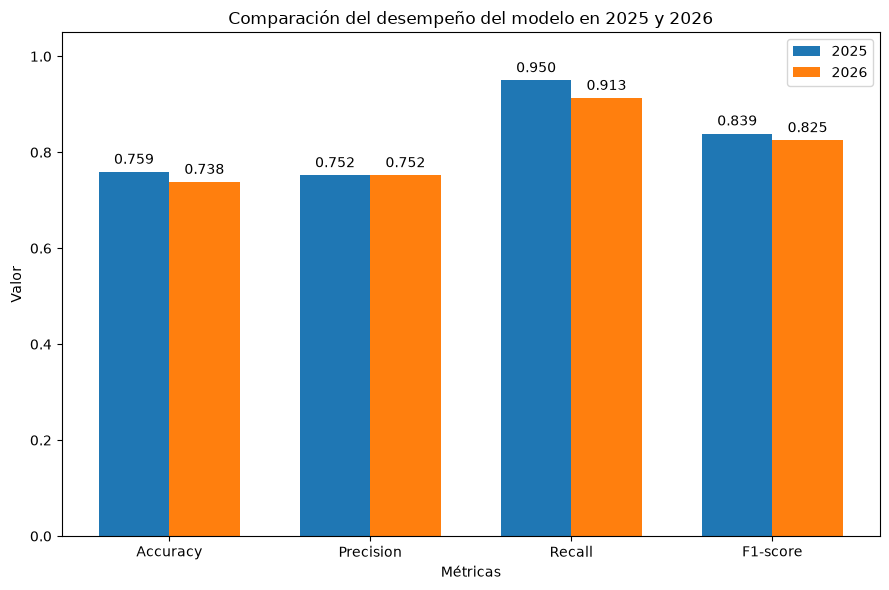

In [54]:
import matplotlib.pyplot as plt
import numpy as np

# Métricas de ambas campañas
metricas = ["Accuracy", "Precision", "Recall", "F1-score"]
valores_2025 = [0.759, 0.752, 0.950, 0.839]
valores_2026 = [0.738, 0.752, 0.913, 0.825]

# Posiciones en el eje x
x = np.arange(len(metricas))
ancho = 0.35

# Crear gráfico
fig, ax = plt.subplots(figsize=(9, 6))

barras_2025 = ax.bar(x - ancho/2, valores_2025, ancho, label="2025")
barras_2026 = ax.bar(x + ancho/2, valores_2026, ancho, label="2026")

# Títulos y etiquetas
ax.set_title("Comparación del desempeño del modelo en 2025 y 2026")
ax.set_xlabel("Métricas")
ax.set_ylabel("Valor")
ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1.05)
ax.legend()

# Mostrar valores sobre las barras
for barra in list(barras_2025) + list(barras_2026):
    altura = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 0.01,
        f"{altura:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Interpretación de la comparación entre 2025 y 2026

La tabla y el gráfico comparativo muestran un desempeño relativamente similar del modelo de regresión logística en las campañas de 2025 y 2026, ambas posteriores al período de entrenamiento.

La exactitud disminuyó del 75,9 % al 73,8 %, mientras que el F1-score de la clase positiva pasó de 0,839 a 0,825. La precisión se mantuvo prácticamente estable en 0,752 y el recall descendió de 0,950 a 0,913.

Aunque se observa una reducción moderada de algunas métricas, el modelo continúa identificando una proporción elevada de lances con registros de bacalao. Sin embargo, en ambas campañas presenta dificultades para clasificar correctamente los lances sin registros de la especie.

Estos resultados aportan evidencia de un comportamiento relativamente consistente en la identificación de la clase positiva, aunque no permiten afirmar que el modelo generalice de igual manera a todas las clases o a futuras campañas.

La comparación debe interpretarse con cautela, especialmente por el carácter preliminar de los datos de 2026.


## Conclusiones generales del proyecto

El proyecto permitió desarrollar y evaluar un modelo de clasificación supervisada para estimar la probabilidad de registrar bacalao del Atlántico (*Gadus morhua*) en lances de investigación pesquera del mar del Norte, utilizando datos de ICES-DATRAS correspondientes al primer trimestre de las campañas 2020–2025.

A partir de la exploración y preparación de los datos, se construyó un conjunto de 1.970 lances válidos. Se seleccionaron tres variables predictoras: profundidad (Depth), latitud (ShootLat) y longitud (ShootLong). El modelo de regresión logística se entrenó con las campañas de 2020 a 2024 y se evaluó inicialmente con los datos de 2025.

En la evaluación principal de 2025, el modelo alcanzó una exactitud del 75,9 % y un F1-score de 0,839 para la clase positiva. Posteriormente, se realizó una evaluación adicional con 324 lances válidos de la campaña preliminar de 2026, obteniendo una exactitud del 73,8 % y un F1-score de 0,825.

La comparación entre ambas campañas mostró un desempeño relativamente consistente para identificar lances con registros de bacalao. El recall de la clase positiva fue del 95,0 % en 2025 y del 91,3 % en 2026. Sin embargo, el modelo presentó mayores dificultades para identificar los lances sin registros de la especie, evidenciando una tendencia a favorecer las predicciones positivas.

Entre las principales limitaciones se encuentran el uso de únicamente tres variables predictoras y el desempeño desigual entre las clases. Además, para aplicar el modelo antes de realizar futuros muestreos sería necesario disponer de estimaciones previas de profundidad del fondo marino, comparables con los valores utilizados durante el entrenamiento. La evaluación de 2026 debe interpretarse con cautela debido al carácter preliminar de los datos publicados por ICES-DATRAS, que podrían estar sujetos a revisiones posteriores.

Como posibles mejoras futuras, se propone incorporar otras variables ambientales disponibles antes del muestreo, ampliar la información histórica y explorar estrategias que permitan mejorar la identificación de los lances sin registros de bacalao, sin comprometer la capacidad de reconocer la clase positiva.

En conclusión, se cumplió el objetivo de desarrollar y evaluar un modelo de clasificación supervisada para estimar registros de bacalao del Atlántico. La evaluación adicional de 2026 aportó evidencia sobre su comportamiento frente a una campaña posterior, permitiendo reconocer tanto sus posibilidades como sus limitaciones. El modelo constituye una aproximación inicial que podría contribuir al análisis y la planificación de futuras campañas, pero no reemplaza los muestreos científicos ni permite determinar la presencia o ausencia real de la especie en una zona.
